# Notebook 3: Demand Forecast
**Question:** How much should we expect to sell each month, and which forecasting method works best?
**Data:** monthly sales from SQL Server. Modeled period: January 2015 to September 2017 (33 months).

In [ ]:
%pip install statsmodels

## 1. Load the data
Pulled total sales for each month from SQL Server (joining `order_items` to `orders`). The result covers January 2015 to January 2018.

In [32]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

engine = create_engine(
    "mssql+pyodbc://localhost\\SQLEXPRESS/supply_chain"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes&TrustServerCertificate=yes"
)

query = """
SELECT YEAR(o.Order_Date) AS Order_Year, MONTH(o.Order_Date) AS Order_Month,
       SUM(oi.Sales) AS Monthly_Sales
FROM order_items oi
JOIN orders o ON oi.Order_Id = o.Order_Id
GROUP BY YEAR(o.Order_Date), MONTH(o.Order_Date)
ORDER BY Order_Year, Order_Month
"""
monthly = pd.read_sql(query, engine)
monthly["Month"] = pd.to_datetime(dict(year=monthly["Order_Year"], month=monthly["Order_Month"], day=1))
all_sales = monthly.set_index("Month")["Monthly_Sales"].astype(float).asfreq("MS")
all_sales.tail()

Month
2017-09-01    1143775.09
2017-10-01    1073994.16
2017-11-01     626914.37
2017-12-01     503910.81
2018-01-01     331650.11
Freq: MS, Name: Monthly_Sales, dtype: float64

## 2. The series and the October 2017 break
Monthly sales are stable at about \$1.04M until September 2017. From October 2017, they fall sharply, but the audit showed this is a change in how the data is structured (one item per order, far fewer products) and not a drop in demand. I model only January 2015 to September 2017.

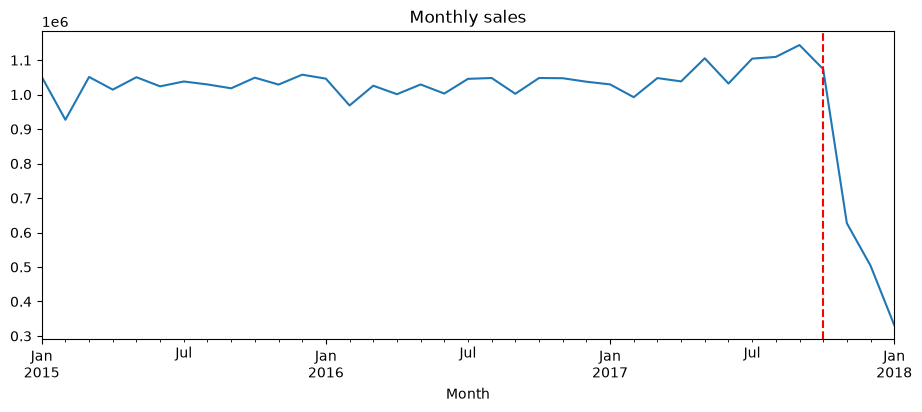

33 months: 2015-01-01 to 2017-09-01


count         33.0
mean     1037826.0
std        40103.0
min       927010.0
25%      1024006.0
50%      1038081.0
75%      1049154.0
max      1143775.0
Name: Monthly_Sales, dtype: float64

In [33]:
ax = all_sales.plot(figsize=(11, 4), title="Monthly sales")
ax.axvline(pd.Timestamp("2017-10-01"), color="red", linestyle="--")
plt.show()

sales = all_sales.loc[:"2017-09"]          # the stable period used for modeling
print(len(sales), "months:", sales.index.min().date(), "to", sales.index.max().date())
sales.describe().round(0)

## 3. Is there seasonality?
Not in the usual sense. February is lower because it has fewer days. Sales per day stay around \$34,000 all year (spread of about 3%). That means the main "seasonal" pattern is the length of the month, which can be handled directly.

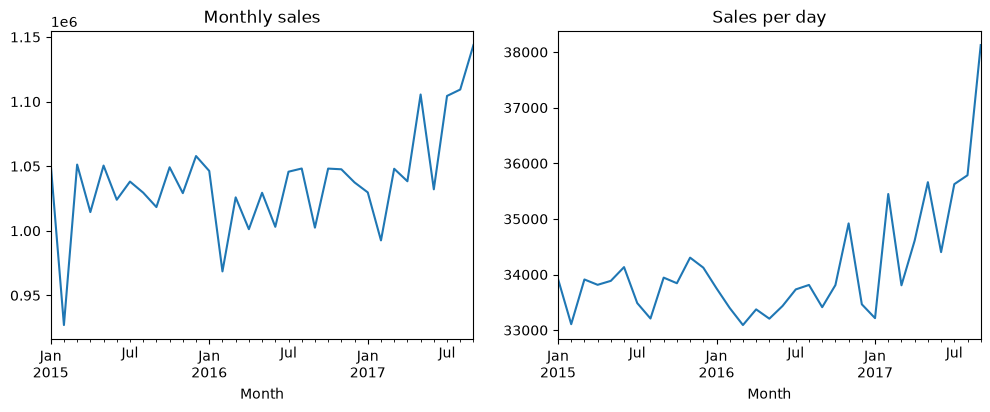

count       33.0
mean     34115.0
std       1039.0
min      33092.0
25%      33435.0
50%      33815.0
75%      34304.0
max      38126.0
dtype: float64

In [34]:
per_day = sales / sales.index.days_in_month
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sales.plot(ax=axes[0], title="Monthly sales")
per_day.plot(ax=axes[1], title="Sales per day")
plt.show()
per_day.describe().round(0)

## 4. Method
Trained on January 2015 to March 2017 (27 months) and tested on April to September 2017 (6 months). Time series are split by date, never randomly. I compared five methods: naive, seasonal naive, a daily-rate method (average sales per day over the last 3 months × days in the month), Holt-Winters, and SARIMA. Error is measured with MAE and MAPE.

In [36]:
train = sales.loc[:"2017-03"]     # Jan 2015 to Mar 2017 (27 months)
test = sales.loc["2017-04":]      # Apr to Sep 2017 (6 months)
print(len(train), len(test))

27 6


In [37]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error

def mape(actual, forecast):
    return float(np.mean(np.abs((np.asarray(actual) - np.asarray(forecast)) / np.asarray(actual))) * 100)

def f_naive(tr, idx, full):
    return pd.Series(tr.iloc[-1], index=idx)

def f_seasonal_naive(tr, idx, full):
    return pd.Series(full.shift(12).loc[idx].values, index=idx)

def f_daily_avg(tr, idx, full):
    rate = (tr / tr.index.days_in_month).iloc[-3:].mean()
    return pd.Series(rate * idx.days_in_month, index=idx)

def f_holt_winters(tr, idx, full):
    fit = ExponentialSmoothing(tr, seasonal="add", seasonal_periods=12).fit()
    return pd.Series(fit.forecast(len(idx)).values, index=idx)

def f_sarima(tr, idx, full):
    fit = SARIMAX(tr, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12)).fit(disp=False)
    return pd.Series(fit.forecast(len(idx)).values, index=idx)

models = {
    "Naive (last month)": f_naive,
    "Seasonal naive (same month last year)": f_seasonal_naive,
    "Daily rate (last 3 months) x days": f_daily_avg,
    "Holt-Winters": f_holt_winters,
    "SARIMA": f_sarima,
}

forecasts, rows = {}, []
for name, fn in models.items():
    f = fn(train, test.index, sales)
    forecasts[name] = f
    rows.append([name, mean_absolute_error(test, f), mape(test, f)])
results = pd.DataFrame(rows, columns=["Model", "MAE ($)", "MAPE (%)"]).sort_values("MAPE (%)")
results.round(1)

,Model,MAE ($),MAPE (%)
2,Daily rate (last 3 months) x days,47114.7,4.2
0,Naive (last month),49425.5,4.4
4,SARIMA,51517.2,4.6
1,Seasonal naive (same month last year),67232.5,6.1
3,Holt-Winters,68397.4,6.2


## 5. Results
The daily-rate method was the most accurate (MAPE 4.2%, versus 4.4% for naive and 6.2% for Holt-Winters). The more complex models did **not** beat simple ones, which makes sense for a flat series with no real seasonality or trend. The test months also ran roughly 6-7% above earlier levels, which no method could anticipate.

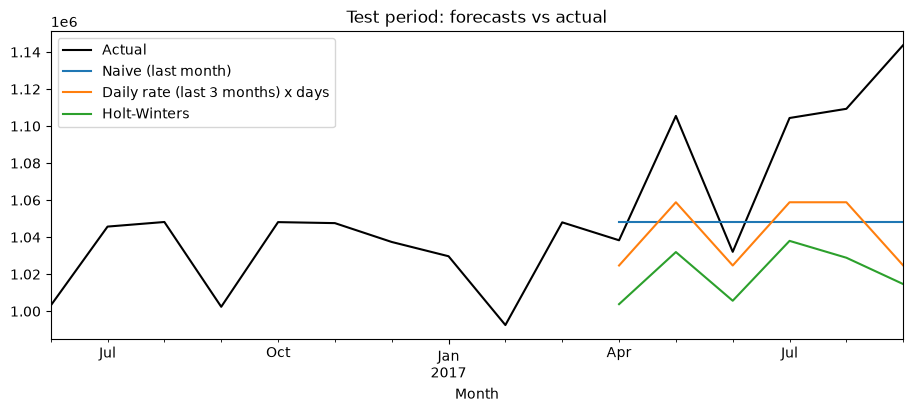

In [44]:
ax = sales.loc["2016-06":].plot(figsize=(11, 4), color="black", label="Actual")
for name in ["Naive (last month)", "Daily rate (last 3 months) x days", "Holt-Winters"]:
    forecasts[name].plot(ax=ax, label=name)
ax.legend(); ax.set_title("Test period: forecasts vs actual")
plt.show()

## 6. Robustness check
Repeating the test from four different starting points, the daily-rate method again came first (average MAPE 3.1% versus 4.3% to 4.5% for the others). Four starting points is a small sample and the differences between the other models are small, so I treat the ranking with caution.

In [41]:
origins = pd.date_range("2016-12-01", "2017-03-01", freq="MS")
roll = {name: [] for name in models}
for o in origins:
    tr = sales.loc[:o]
    te = sales.loc[o + pd.offsets.MonthBegin(1):].iloc[:6]
    for name, fn in models.items():
        roll[name].append(mape(te, fn(tr, te.index, sales)))
pd.DataFrame({"Avg MAPE (%)": {k: np.mean(v) for k, v in roll.items()}}).sort_values("Avg MAPE (%)").round(1)

,Avg MAPE (%)
Daily rate (last 3 months) x days,3.1
Naive (last month),4.3
Seasonal naive (same month last year),4.4
SARIMA,4.5
Holt-Winters,4.5


## 7. Final forecast (October 2017 to March 2018)

**Method:** the daily-rate method, which takes the average sales per day over the last three months of the stable data (July to September 2017, about \$36,500 a day) and multiplies it by the number of days in each month. The shaded band is an approximate 95% range, calculated as the forecast ± 1.96 × the test-set RMSE (about \$59,000, so roughly ±\$117,000).

**Forecast:** about **\$1.13M** in every 31-day month, about **\$1.10M** in November (30 days), and about **\$1.02M** in February (28 days).

| Month | Forecast | Actual |
|---|---|---|
| Oct 2017 | \$1,131,870 | \$1,073,994 |
| Nov 2017 | \$1,095,359 | \$626,914 |
| Dec 2017 | \$1,131,870 | \$503,911 |
| Jan 2018 | \$1,131,870 | \$331,650 |
| Feb 2018 | \$1,022,335 | not in data |
| Mar 2018 | \$1,131,870 | not in data |

**How to read the gap:** October was only about 5% below the forecast, but November to January fall far below it. This is the structural break found in the audit (one item per order and far fewer products), not a forecasting failure, so the forecast should be read as "business as usual if the earlier pattern had continued."

**Limits:** the last three months used to set the daily rate were the highest of the series (about \$36,500 a day, versus about \$34,000 over the full period), so this forecast sits about 7% above the long-run average. The band is approximate and assumes errors similar to the test period. Only 33 months of history were available, and the method was chosen after looking at results on the same data.

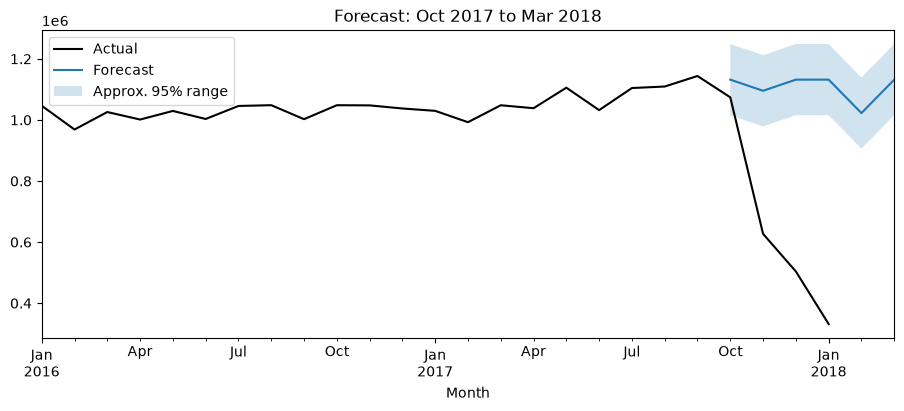

,Forecast,Actual
2017-10-01,1131870.0,1073994.0
2017-11-01,1095359.0,626914.0
2017-12-01,1131870.0,503911.0
2018-01-01,1131870.0,331650.0
2018-02-01,1022335.0,NaN
2018-03-01,1131870.0,NaN


In [42]:
future = pd.date_range("2017-10-01", "2018-03-01", freq="MS")
fc = f_daily_avg(sales, future, sales)

test_fc = forecasts["Daily rate (last 3 months) x days"]
rmse = float(np.sqrt(np.mean((test.values - test_fc.values) ** 2)))

ax = all_sales.loc["2016-01":].plot(figsize=(11, 4), color="black", label="Actual")
fc.plot(ax=ax, color="tab:blue", label="Forecast")
ax.fill_between(fc.index, fc - 1.96 * rmse, fc + 1.96 * rmse, alpha=0.2, label="Approx. 95% range")
ax.legend(); ax.set_title("Forecast: Oct 2017 to Mar 2018")
plt.show()

pd.DataFrame({"Forecast": fc.round(0), "Actual": all_sales.reindex(future).round(0)})

## Conclusions
1. Demand is steady at about \$34,000 a day (about \$1.04M a month), with recent months running closer to \$36,500 a day.
2. The daily-rate method, which adjusts for days in the month, was the most accurate in both tests, ahead of the naive baseline and well ahead of Holt-Winters and SARIMA. Complex models did not help on this flat series.
3. For planning, use about \$34K a day as the long-run baseline (recent months ran closer to \$36.5K), and investigate why the data changes in October 2017 before trusting later months.
4. The ranking comes from a small sample (one 6-month test plus four rolling starts), so differences between the close methods should not be over-read.